# 09 — Simulasi genangan (pengganti ModelBuilder)

| ModelBuilder (paper) | Python |
| --- | --- |
| Topo to Raster | DEM 8 m dari notebook 02 |
| Fill | `skimage.morphology.reconstruction` |
| Int | `np.floor(dem)` |
| Extract by Attributes | `mask = dem_int <= level` |
| Raster to Polygon | `rasterio.features.shapes` → `geopandas` |
| CGA `touches(all, "water14")` | `geopandas.sjoin(buildings, flood, predicate="intersects")` |

Perbaikan atas paper:
- Hanya sel yang terhubung ke sumber air (danau UI dari OSM) yang tergenang (`scipy.ndimage.label`).
  Versi paper (ambang saja, "naive") tetap dihitung sebagai pembanding.
- DEM bersifat DSM: piksel bangunan dimasking lalu diinterpolasi agar mendekati DTM.

Ini skenario visual berbasis ambang, bukan prediksi banjir hidrologis.

**Output**: `output/flood_levels.gpkg`, `output/flood_impact.csv`, `output/flood_3d.html`, grafik dan peta.

In [1]:
import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pydeck as pdk
import rasterio
from matplotlib.patches import Patch
from rasterio.features import rasterize, shapes
from scipy import ndimage
from scipy.interpolate import griddata
from shapely.geometry import shape
from skimage.morphology import reconstruction

from ui3d_common import CFG, CRS, aoi, out, savefig

Fc = CFG["flood"]
gdb = out("ui3d.gpkg")
bld = gpd.read_file(gdb, layer="buildings")
water = gpd.read_file(gdb, layer="water")
aoi_buf = aoi("aoi_buf50")

## Topo to Raster: DEM 8 m dipotong ke AOI + 200 m

In [2]:
with rasterio.open(out("dem_ui_8m.tif")) as s:
    win = rasterio.windows.from_bounds(*aoi_buf.buffer(200).total_bounds, s.transform).round_offsets().round_lengths()
    dem = s.read(1, window=win)
    tr = s.window_transform(win)
shape_ = dem.shape
print("DEM", shape_, f"{np.nanmin(dem):.1f}–{np.nanmax(dem):.1f} m")

DEM (461, 250) 40.1–93.0 m


## DSM → mendekati DTM: masking bangunan + interpolasi

In [3]:
bmask = rasterize([(g, 1) for g in bld.buffer(Fc["building_mask_buffer_m"])], out_shape=shape_, transform=tr,
                  dtype="uint8", all_touched=True).astype(bool)
bad = bmask | np.isnan(dem)
rr, cc = np.indices(shape_)
dtm = dem.copy()
dtm[bad] = griddata((rr[~bad], cc[~bad]), dem[~bad], (rr[bad], cc[bad]), method="linear")
still = np.isnan(dtm)
dtm[still] = griddata((rr[~bad], cc[~bad]), dem[~bad], (rr[still], cc[still]), method="nearest")
print(f"Piksel bangunan diinterpolasi: {bmask.mean():.1%}")

Piksel bangunan diinterpolasi: 11.7%


## Fill → Int

In [4]:
seed = dtm.copy()
seed[1:-1, 1:-1] = dtm.max()
filled = reconstruction(seed, dtm, method="erosion")
dem_int = np.floor(filled)

inside = rasterize([(aoi_buf.geometry.iloc[0], 1)], out_shape=shape_, transform=tr, dtype="uint8").astype(bool)
lo, hi = np.percentile(filled[inside], Fc["level_percentiles"])
levels = np.arange(np.floor(lo), np.ceil(hi) + Fc["level_step_m"], Fc["level_step_m"])
print("Level muka air (m):", levels)

src_water = rasterize([(g, 1) for g in water.geometry], out_shape=shape_, transform=tr, dtype="uint8",
                      all_touched=True).astype(bool)
print("Piksel sumber air (danau/sungai OSM):", int(src_water.sum()))

Level muka air (m): [54. 55. 56. 57. 58. 59. 60. 61. 62. 63. 64. 65.]
Piksel sumber air (danau/sungai OSM): 4576


## Extract by Attributes → konektivitas → Raster to Polygon → bangunan terdampak

In [5]:
def polygonize(mask, level, method):
    geoms = [shape(g) for g, _ in shapes(mask.astype(np.uint8), mask=mask, transform=tr)]
    return gpd.GeoDataFrame({"level_m": [level] * len(geoms), "method": method}, geometry=geoms, crs=CRS)


def affected(flood):
    if flood.empty:
        return set()
    j = gpd.sjoin(bld[["geometry"]], flood[["geometry"]], predicate="intersects")
    return set(j.index)


polys, impact, hit = [], [], {}
for lv in levels:
    naive = (dem_int <= lv) & inside
    lab, _ = ndimage.label(dem_int <= lv)
    ids = np.unique(lab[src_water & (lab > 0)])
    conn = np.isin(lab, ids) & inside if len(ids) else np.zeros_like(naive)
    fn, fc = polygonize(naive, lv, "naive"), polygonize(conn, lv, "connected")
    polys += [fn, fc]
    hit[lv] = affected(fc)
    impact.append(dict(level_m=lv, gedung_naive=len(affected(fn)), gedung_terhubung=len(hit[lv]),
                       luas_naive_ha=naive.sum() * abs(tr.a * tr.e) / 1e4,
                       luas_terhubung_ha=conn.sum() * abs(tr.a * tr.e) / 1e4))

flood = pd.concat(polys, ignore_index=True)
flood = gpd.GeoDataFrame(flood, geometry="geometry", crs=CRS)
out("flood_levels.gpkg").unlink(missing_ok=True)
for m in ("connected", "naive"):
    flood[flood.method == m].to_file(out("flood_levels.gpkg"), layer=m)
impact = pd.DataFrame(impact).round(2)
impact.to_csv(out("flood_impact.csv"), index=False)
impact

,level_m,gedung_naive,gedung_terhubung,luas_naive_ha,luas_terhubung_ha
0,54.0,8,8,18.44,18.41
1,55.0,10,10,20.66,20.66
2,56.0,15,15,22.46,22.46
3,57.0,21,21,24.27,24.14
4,58.0,38,35,26.35,26.30
5,59.0,87,87,29.99,29.99
6,60.0,188,188,36.99,36.99
7,61.0,306,306,46.68,46.68
8,62.0,353,353,53.79,53.79
9,63.0,393,393,61.21,61.21


## Gedung terdampak per level (setara Fig. 23)

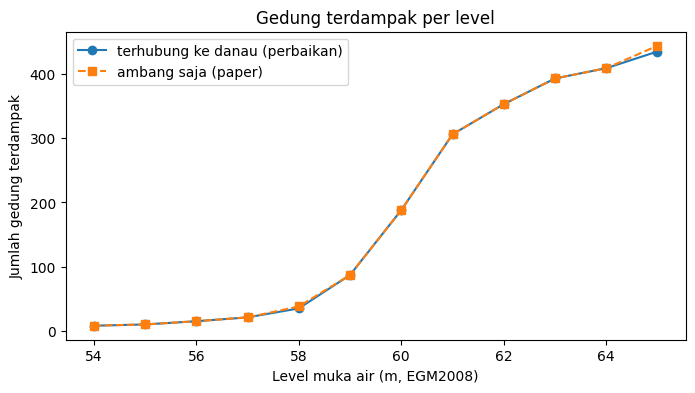

In [6]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(impact.level_m, impact.gedung_terhubung, "o-", label="terhubung ke danau (perbaikan)")
ax.plot(impact.level_m, impact.gedung_naive, "s--", label="ambang saja (paper)")
ax.set(xlabel="Level muka air (m, EGM2008)", ylabel="Jumlah gedung terdampak", title="Gedung terdampak per level")
ax.legend()
savefig(fig, "fig23_gedung_terdampak.png")
plt.show()

## Peta merah/kuning (setara Fig. 24): merah = terdampak, kuning = aman

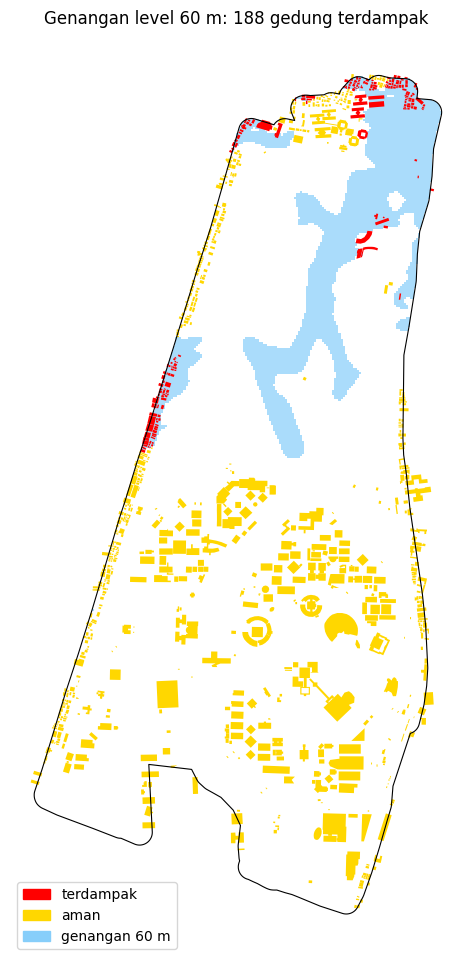

In [7]:
LV = Fc["map_level"] if Fc["map_level"] is not None else float(levels[len(levels) // 2])
LV = float(levels[np.argmin(np.abs(levels - LV))])
is_hit = bld.index.isin(hit[LV])
fl = flood[(flood.method == "connected") & (flood.level_m == LV)]

fig, ax = plt.subplots(figsize=(8, 12))
aoi_buf.boundary.plot(ax=ax, color="k", lw=0.8)
fl.plot(ax=ax, color="lightskyblue", alpha=0.7)
bld[~is_hit].plot(ax=ax, color="gold")
bld[is_hit].plot(ax=ax, color="red")
ax.legend(handles=[Patch(color="red", label="terdampak"), Patch(color="gold", label="aman"),
                   Patch(color="lightskyblue", label=f"genangan {LV:.0f} m")], loc="lower left")
ax.set_title(f"Genangan level {LV:.0f} m: {is_hit.sum()} gedung terdampak")
ax.set_axis_off()
savefig(fig, "fig24_peta_genangan.png")
plt.show()

## Versi 3D di pydeck

In [8]:
b4 = bld.to_crs(4326).explode(index_parts=False)
hit_ids = set(hit[LV])
df = pd.DataFrame({"name": b4["name"].fillna("").values, "Bld_Height": b4.Bld_Height.values,
                   "status": ["terdampak" if i in hit_ids else "aman" for i in b4.index],
                   "polygon": [[[list(p[:2]) for p in g.exterior.coords]] for g in b4.geometry]})
df["color"] = df.status.map({"terdampak": [220, 30, 30], "aman": [240, 200, 40]})
f4 = fl.to_crs(4326).explode(index_parts=False)
fdf = pd.DataFrame({"polygon": [[[list(p[:2]) for p in g.exterior.coords]] for g in f4.geometry]})
c = b4.union_all().centroid
deck = pdk.Deck(
    layers=[pdk.Layer("PolygonLayer", fdf, get_polygon="polygon", get_fill_color=[80, 160, 255, 140]),
            pdk.Layer("PolygonLayer", df, get_polygon="polygon", extruded=True, get_elevation="Bld_Height",
                      get_fill_color="color", pickable=True)],
    initial_view_state=pdk.ViewState(longitude=c.x, latitude=c.y, zoom=15.5, pitch=50),
    map_provider="carto", map_style="light",
    tooltip={"text": "{name}\n{status}\nTinggi {Bld_Height} m"},
)
deck.to_html(str(out("flood_3d.html")), open_browser=False)
deck

{
  "initialViewState": {
    "latitude": -6.3632481623242345,
    "longitude": 106.82740489533633,
    "pitch": 50,
    "zoom": 15.5
  },
  "layers": [
    {
      "@@type": "PolygonLayer",
      "data": [
        {
          "polygon": [
            [
              [
                106.82830667055539,
                -6.346351218857347
              ],
              [
                106.82830692565754,
                -6.346423551402241
              ],
              [
                106.82809003386767,
                -6.346424317041331
              ],
              [
                106.82809028894256,
                -6.346496649594808
              ],
              [
                106.82830718076268,
                -6.346495883946923
              ],
              [
                106.82830743587077,
                -6.346568216491392
              ],
              [
                106.82852432769438,
                -6.346567450743998
              ],
              [
                106.82852381742072,
                -6.34642278567244
              ],
              [
                106.82859611466918,
                -6.346422530409013
              ],
              [
                106.82859585952673,
                -6.346350197875847
              ],
              [
                106.82830667055539,
                -6.346351218857347
              ]
            ]
          ]
        },
        {
          "polygon": [
            [
              [
                106.82628540446397,
                -6.347226352721826
              ],
              [
                106.82628565931964,
                -6.347298685346228
              ],
              [
                106.8262133618554,
                -6.347298940322269
              ],
              [
                106.82621361670392,
                -6.347371272949388
              ],
              [
                106.82614131922664,
                -6.347371527918276
              ],
              [
                106.82614182891247,
                -6.347516193177735
              ],
              [
                106.82606953141206,
                -6.3475164481424
              ],
              [
                106.82607029593278,
                -6.347733446038785
              ],
              [
                106.8259979983992,
                -6.347733701002154
              ],
              [
                106.82599876291636,
                -6.34795069890542
              ],
              [
                106.82592646534957,
                -6.347950953867492
              ],
              [
                106.82592748470697,
                -6.348240284413926
              ],
              [
                106.82599978231406,
                -6.348240029440141
              ],
              [
                106.82599952746017,
                -6.348167696806778
              ],
              [
                106.82607182505423,
                -6.348167441825839
              ],
              [
                106.82607157019325,
                -6.348095109195193
              ],
              [
                106.8262161653523,
                -6.348094599208928
              ],
              [
                106.82621591047412,
                -6.348022266583926
              ],
              [
                106.8266496958197,
                -6.348020736400742
              ],
              [
                106.82664995075832,
                -6.348093069008171
              ],
              [
                106.82686684342131,
                -6.348092303771691
              ],
              [
                106.82686709839315,
                -6.348164636370116
              ],
              [
                106.82701169350715,
                -6.348164126156194
              ],
              [
                106.82701194850209,
                -6.348236458748551
              ],
              [
               